In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [29]:
df = sns.load_dataset("diamonds")
df

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...
53935,0.72,Ideal,D,SI1,60.8,57.0,2757,5.75,5.76,3.50
53936,0.72,Good,D,SI1,63.1,55.0,2757,5.69,5.75,3.61
53937,0.70,Very Good,D,SI1,62.8,60.0,2757,5.66,5.68,3.56
53938,0.86,Premium,H,SI2,61.0,58.0,2757,6.15,6.12,3.74


In [30]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.0 MB


In [31]:
df.shape

(53940, 10)

In [32]:
df.describe()

,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


In [33]:
df.isnull().sum()

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64

In [34]:
df.duplicated()

0        False
1        False
2        False
3        False
4        False
         ...  
53935    False
53936    False
53937    False
53938    False
53939    False
Length: 53940, dtype: bool

#Cleaning

In [35]:
bad_data=df[(df['x']==0)| (df['y']==0)| (df['z']==0)]
print(f'Number of rows with bad data :{bad_data}')

Number of rows with bad data :       carat        cut color clarity  depth  table  price     x     y    z
2207    1.00    Premium     G     SI2   59.1   59.0   3142  6.55  6.48  0.0
2314    1.01    Premium     H      I1   58.1   59.0   3167  6.66  6.60  0.0
4791    1.10    Premium     G     SI2   63.0   59.0   3696  6.50  6.47  0.0
5471    1.01    Premium     F     SI2   59.2   58.0   3837  6.50  6.47  0.0
10167   1.50       Good     G      I1   64.0   61.0   4731  7.15  7.04  0.0
11182   1.07      Ideal     F     SI2   61.6   56.0   4954  0.00  6.62  0.0
11963   1.00  Very Good     H     VS2   63.3   53.0   5139  0.00  0.00  0.0
13601   1.15      Ideal     G     VS2   59.2   56.0   5564  6.88  6.83  0.0
15951   1.14       Fair     G     VS1   57.5   67.0   6381  0.00  0.00  0.0
24394   2.18    Premium     H     SI2   59.4   61.0  12631  8.49  8.45  0.0
24520   1.56      Ideal     G     VS2   62.2   54.0  12800  0.00  0.00  0.0
26123   2.25    Premium     I     SI1   61.3   58.0  15397

In [36]:
print(f'Number of rows with bad data :{len(bad_data)}')

Number of rows with bad data :20


In [ ]:
df_cleaned=df[(df['x']>0)& (df['y']>0)& (df['z']>0)]
print(df_cleaned.shape)

(53920, 10)


In [38]:
df_cleaned['volume']=df_cleaned['x']*df_cleaned['y']*df_cleaned['z']
volume_price_corr=df_cleaned['volume'].corr(df_cleaned['price'])
print(f'Colleration between Volume and Price : {volume_price_corr:.4f}')

Colleration between Volume and Price : 0.9043


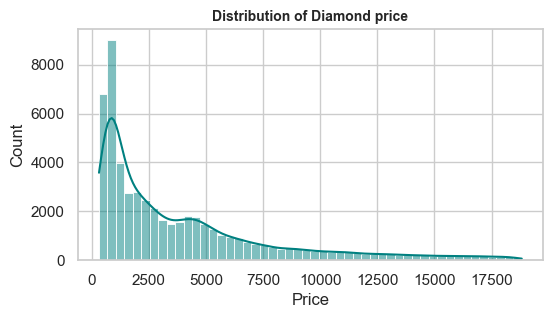

In [39]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(6,3))
sns.histplot(df_cleaned['price'],bins=50,kde=True,color='teal')
plt.title('Distribution of Diamond price',fontsize=10,fontweight='bold')
plt.xlabel('Price')
plt.ylabel('Count')
plt.show()

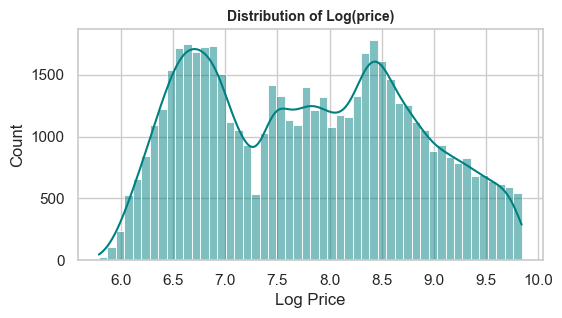

In [40]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(6,3))
sns.histplot(np.log(df_cleaned['price']),bins=50,kde=True,color='teal')
plt.title('Distribution of Log(price)',fontsize=10,fontweight='bold')
plt.xlabel('Log Price')
plt.ylabel('Count')
plt.show()

Number of rows flagged as outliers : 3532


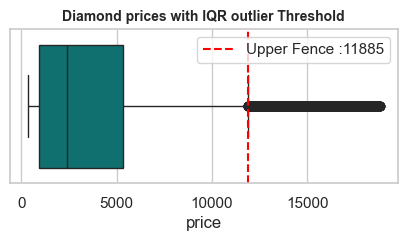

In [48]:
sns.set_theme(style="whitegrid")
Q1=df_cleaned['price'].quantile(0.25)
Q3=df_cleaned['price'].quantile(0.75)
IQR= Q3-Q1
lower_bound=Q1 - 1.5 * IQR
upper_bound=Q3 + 1.5 * IQR
outliers=df_cleaned[(df_cleaned['price']<lower_bound) | (df_cleaned['price']>upper_bound)]
print(f'Number of rows flagged as outliers : {len(outliers)}')
plt.figure(figsize=(5,2))
sns.boxplot(x=df_cleaned['price'],color='teal')
plt.axvline(upper_bound,color='red',linestyle='--',label=f'Upper Fence :{upper_bound:.0f}')
plt.title('Diamond prices with IQR outlier Threshold',fontsize=10,fontweight='bold')
plt.xlabel('price')
plt.legend()
plt.show()

In [42]:
cut_analysis=df_cleaned.groupby('cut',observed=False)[['price','carat']].mean().reset_index()
print(cut_analysis.round(3))

         cut     price  carat
0      Ideal  3456.941  0.703
1    Premium  4579.685  0.891
2  Very Good  3981.664  0.806
3       Good  3926.404  0.849
4       Fair  4357.501  1.046


C:\Users\Houria\AppData\Local\Temp\ipykernel_8760\3032473003.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df,x='clarity',y='price',order=clarity_ranking,palette='pastel')


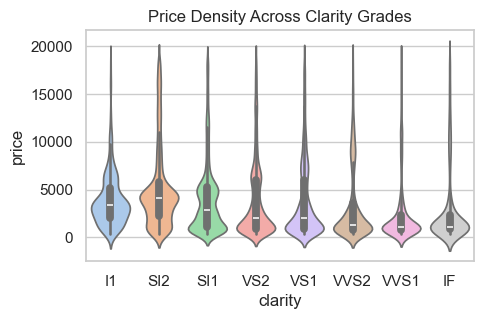

In [43]:
sns.set_theme(style='whitegrid')
clarity_ranking=["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"]
plt.figure(figsize=(5,3))
sns.violinplot(data=df,x='clarity',y='price',order=clarity_ranking,palette='pastel')
plt.title('Price Density Across Clarity Grades')
plt.show()

In [44]:
heighest_combination=df.groupby(['cut','color'])['price'].mean().sort_values(ascending=False)
print(heighest_combination.head(1))

cut      color
Premium  J        6294.591584
Name: price, dtype: float64


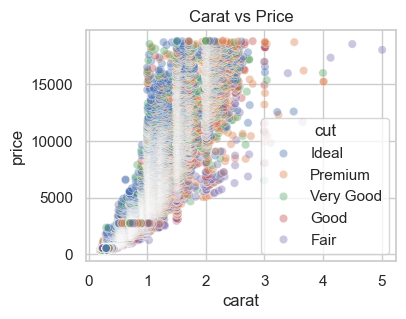

In [45]:
sns.set_theme(style='whitegrid')
plt.figure(figsize=(4,3))
sns.scatterplot(data=df,x='carat',y='price',hue='cut',alpha=0.4)
plt.title('Carat vs Price')
plt.show()

In [46]:
df['carat_bucket']=(df['carat']*2).round()/2
avg_price=df.groupby('carat_bucket')['price'].mean()
print(avg_price)

carat_bucket
0.0      506.132484
0.5     1345.079387
1.0     5216.769999
1.5     9968.707581
2.0    14456.927388
2.5    15493.206250
3.0    14241.058824
3.5    15022.600000
4.0    15939.750000
4.5    18531.000000
5.0    18018.000000
Name: price, dtype: float64


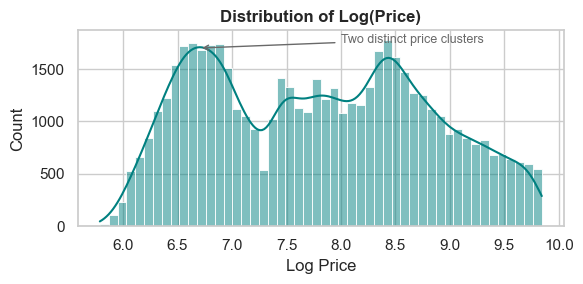

In [56]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(6,3))
sns.histplot(np.log(df_cleaned['price']), bins=50, kde=True, color='teal')
plt.title('Distribution of Log(Price)', fontsize=12, fontweight='bold')
plt.xlabel('Log Price')
plt.ylabel('Count')
# annotate the bimodal insight directly on the chart
plt.annotate('Two distinct price clusters',xy=(6.7,1700),xytext=(8.0,1750),fontsize=9,color='dimgray',arrowprops=dict(arrowstyle='->',color='dimgray'))
plt.tight_layout()
plt.savefig('log_price_distribution.png', dpi=300, bbox_inches='tight')

plt.show()

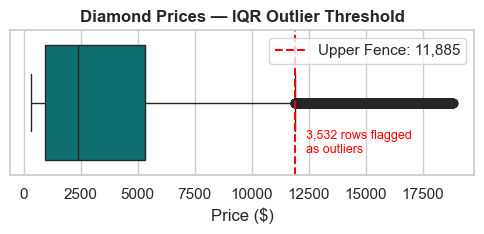

In [55]:
sns.set_theme(style="whitegrid")
Q1 = df_cleaned['price'].quantile(0.25)
Q3 = df_cleaned['price'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = df_cleaned[(df_cleaned['price'] < lower_bound) | (df_cleaned['price'] > upper_bound)]
plt.figure(figsize=(5,2.5))
sns.boxplot(x=df_cleaned['price'], color='teal')
plt.axvline(upper_bound, color='red', linestyle='--',label=f'Upper Fence: {upper_bound:,.0f}')
plt.title('Diamond Prices — IQR Outlier Threshold', fontsize=12, fontweight='bold')
plt.xlabel('Price ($)')
# put the flagged-count directly on the chart instead of only in print()
plt.text(upper_bound + 500, 0.35, f'{len(outliers):,} rows flagged\nas outliers',fontsize=9, color='red')
plt.legend()
plt.tight_layout()
plt.show()